# 18 · Ablation and contribution checks

## Purpose

Test the proposed combination as an empirical ablation of standard components, without claiming global novelty.

## Method

Compare probability-ranking, calibration, cost-sensitive selection, the combined calibrated cost strategy, and uncertainty-first review on the decision-study holdout; report AUC, PR-AUC, Brier, log loss, precision/recall@K, cost, and runtime.

## Interpretation

Use the displayed tables, figures, and saved metrics produced by this run. Do not fill this section with assumed outcomes. For every result, distinguish observed evidence from interpretation.

## Limitations

One holdout does not prove stability. Cost-sensitive ranking can be monotonic in probability for fixed costs, so equal rankings are a possible and informative result.

## References

Related established components and the novelty boundary are summarized in docs/references.md.


In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd().resolve()
while not (ROOT / 'returnwise').is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from IPython.display import display
from returnwise.research_state import load_state, save_state
state = load_state()
print('Project:', ROOT)
print('Notebook:', '18 · Ablation and contribution checks')


Project: C:\Users\Lenovo\Documents\Who is back
Notebook: 18 · Ablation and contribution checks


,experiment,strategy,capacity_percent,capacity_rows,review_count,false_positive_cost_assumption,false_negative_cost_assumption,review_cost_assumption,expected_decision_cost,false_positives,false_negatives,return_cases_identified,precision_at_k,recall_at_k,count_type,roc_auc,pr_auc,brier_score,log_loss,runtime_seconds
0,A: probability-ranking baseline,probability_only,5.0,1600,1600,1.0,5.0,0.25,71533.0,533,14120,1067,0.666875,0.070257,observed on labeled validation data,0.592534,0.557368,0.243004,0.678976,1.304221
1,A: probability-ranking baseline,probability_only,10.0,3200,3200,1.0,5.0,0.25,68139.0,1234,13221,1966,0.614375,0.129453,observed on labeled validation data,0.592534,0.557368,0.243004,0.678976,1.304221
2,A: probability-ranking baseline,probability_only,20.0,6400,6400,1.0,5.0,0.25,61513.0,2663,11450,3737,0.583906,0.246066,observed on labeled validation data,0.592534,0.557368,0.243004,0.678976,1.304221
3,A: probability-ranking baseline,probability_only,30.0,9600,9600,1.0,5.0,0.25,55397.0,4177,9764,5423,0.564896,0.357082,observed on labeled validation data,0.592534,0.557368,0.243004,0.678976,1.304221
4,B: calibration,probability_only,5.0,1600,1600,1.0,5.0,0.25,71533.0,533,14120,1067,0.666875,0.070257,observed on labeled validation data,0.592534,0.557368,0.242690,0.678313,0.868665
5,B: calibration,probability_only,10.0,3200,3200,1.0,5.0,0.25,68139.0,1234,13221,1966,0.614375,0.129453,observed on labeled validation data,0.592534,0.557368,0.242690,0.678313,0.868665
6,B: calibration,probability_only,20.0,6400,6400,1.0,5.0,0.25,61513.0,2663,11450,3737,0.583906,0.246066,observed on labeled validation data,0.592534,0.557368,0.242690,0.678313,0.868665
7,B: calibration,probability_only,30.0,9600,9600,1.0,5.0,0.25,55397.0,4177,9764,5423,0.564896,0.357082,observed on labeled validation data,0.592534,0.557368,0.242690,0.678313,0.868665
8,C: cost-sensitive,cost_sensitive,5.0,1600,1600,1.0,5.0,0.25,71533.0,533,14120,1067,0.666875,0.070257,observed on labeled validation data,0.592534,0.557368,0.243004,0.678976,0.798401
9,C: cost-sensitive,cost_sensitive,10.0,3200,3200,1.0,5.0,0.25,68139.0,1234,13221,1966,0.614375,0.129453,observed on labeled validation data,0.592534,0.557368,0.243004,0.678976,0.798401


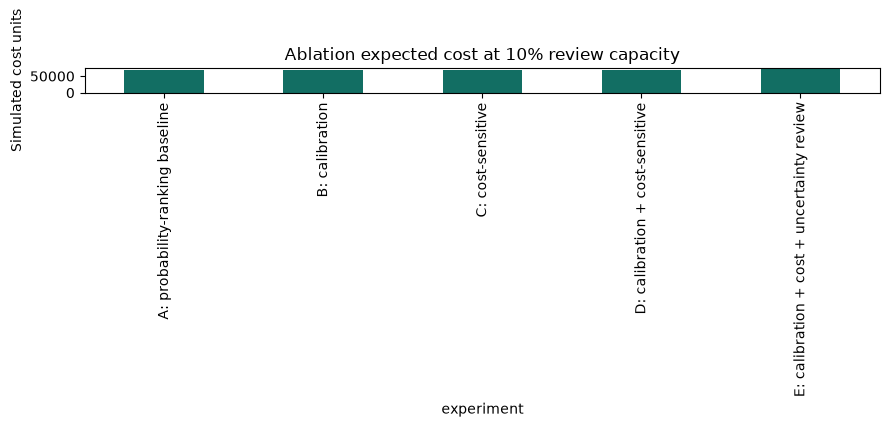

In [2]:
from returnwise.experiments import ablation_table
from returnwise.research_state import load_state, save_state
import matplotlib.pyplot as plt

state = load_state()
predictions = state['decision_predictions']
predictions.attrs['selected_calibrator'] = state['decision_calibrator_name']
ablation = ablation_table(predictions, costs=state['cost_scenarios']['medium'])
display(ablation)
if 'expected_decision_cost' in ablation:
    plot_data = ablation[ablation['capacity_percent'] == 10]
    ax = plot_data.plot.bar(x='experiment', y='expected_decision_cost', figsize=(9, 4), legend=False, color='#126E63', title='Ablation expected cost at 10% review capacity')
    ax.set_ylabel('Simulated cost units')
    plt.tight_layout()
    plt.show()
state['ablation'] = ablation
from returnwise.experiments import log_experiment
log_experiment('Ablation study', None, {'results': ablation.to_dict(orient='records')},
               {'costs_are_simulated': True, 'decision_holdout_rows': len(predictions)})
save_state(state)
